# DL091 预测世界模型与模型式决策

本Notebook在新Python进程的真实IPython内核内顺序执行，完整运行实验和测试。先读 lecture.md 与 lab.md。只验证离线合成教学任务，不代表自然数据性能或部署保证。

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import experiment as exp
print("Python",sys.version.split()[0],"NumPy",np.__version__)

Python 3.12.14 NumPy 2.3.5


## 完整重训与数据保存
运行覆盖本目录 outputs 和 figures 中的同名文件；无下载、无GPU、无付费API。

In [2]:
result=exp.main("outputs")

{
  "control": {
    "multi_step": {
      "mean_cost": 15.632046639932122,
      "failure_rate": 0.0
    },
    "one_step": {
      "mean_cost": 15.645081035230332,
      "failure_rate": 0.0
    },
    "oracle": {
      "mean_cost": 16.958254690920487,
      "failure_rate": 0.0
    },
    "oracle_short": {
      "mean_cost": 44.527184608299564,
      "failure_rate": 1.0
    },
    "partial": {
      "mean_cost": 45.15940969444253,
      "failure_rate": 1.0
    },
    "pd": {
      "mean_cost": 14.800829752513328,
      "failure_rate": 0.0
    },
    "zero": {
      "mean_cost": 36.79945868001432,
      "failure_rate": 1.0
    }
  },
  "partial": {
    "position_only_mse": 0.0020831914769737646,
    "history_mse": 5.911967405631354e-07,
    "same_x_opposite_velocity_next_x": [
      1.075,
      0.925
    ]
  },
  "seconds": 1.3695476670109201
}


## 手算对应的真实一步与隐藏速度

In [3]:
print(exp.true_step(np.array([1.,0.]),0.))
print(exp.true_step(np.array([[1.,.5],[1.,-.5]]),np.zeros(2)))
s,a=exp.generate(9101)
s0,aa,target=exp.windows(s,a,5)
print("trajectory",s.shape,"windows",s0.shape,aa.shape,target.shape)

[ 1.   -0.06]
[[ 1.075  0.415]
 [ 0.925 -0.535]]
trajectory (48, 41, 2) windows (1728, 2) (1728, 5) (1728, 5, 2)


## 训练目标与控制结果

In [4]:
for row in result["runs"]:
    print(row["method"],row["seed"],"training five-step MSE",row["training_five_step_mse"])
print(json.dumps(result["control_summary"],indent=2))
print(result["partial_observation"])

one_step 11 training five-step MSE 0.00010397132017638291
multi_step 11 training five-step MSE 0.00010288441007351876
one_step 23 training five-step MSE 0.0001495827971635046
multi_step 23 training five-step MSE 0.00014828279493016248
one_step 37 training five-step MSE 0.00011504702943803595
multi_step 37 training five-step MSE 0.0001146645182603937
{
  "multi_step": {
    "mean_cost": 15.632046639932122,
    "failure_rate": 0.0
  },
  "one_step": {
    "mean_cost": 15.645081035230332,
    "failure_rate": 0.0
  },
  "oracle": {
    "mean_cost": 16.958254690920487,
    "failure_rate": 0.0
  },
  "oracle_short": {
    "mean_cost": 44.527184608299564,
    "failure_rate": 1.0
  },
  "partial": {
    "mean_cost": 45.15940969444253,
    "failure_rate": 1.0
  },
  "pd": {
    "mean_cost": 14.800829752513328,
    "failure_rate": 0.0
  },
  "zero": {
    "mean_cost": 36.79945868001432,
    "failure_rate": 1.0
  }
}
{'position_only_mse': 0.0020831914769737646, 'history_mse': 5.911967405631354e-0

## 单元测试
检查计算与边界，不只观察训练损失。

In [5]:
import unittest
suite=unittest.defaultTestLoader.discover(str(Path.cwd()),pattern="test_experiment.py")
check=unittest.TextTestRunner(verbosity=2).run(suite)
if not check.wasSuccessful(): raise RuntimeError("tests failed")

test_action_bounds (test_experiment.TestDynamics.test_action_bounds) ... 

ok


test_candidates (test_experiment.TestDynamics.test_candidates) ... 

ok


test_determinism (test_experiment.TestDynamics.test_determinism) ... 

...

test_rollout_true (test_experiment.TestDynamics.test_rollout_true) ... 

ok


test_shape (test_experiment.TestDynamics.test_shape) ... 

ok


----------------------------------------------------------------------
Ran 10 tests in 0.022s

OK


## 保存文件的独立推理重放

In [6]:
import verify_replay
replay=verify_replay.main("outputs")
print(replay)

{"status": "passed", "model_domain_predictions_replayed": 18, "control_episodes_replayed": 84, "max_prediction_error": 0.0, "max_true_dynamics_residual": 0.0, "cost_failure_action_replay": "passed"}
{'status': 'passed', 'model_domain_predictions_replayed': 18, 'control_episodes_replayed': 84, 'max_prediction_error': 0.0, 'max_true_dynamics_residual': 0.0, 'cost_failure_action_replay': 'passed'}


## 原创图的真实结果
图为本次实验直接重建。

01_rollout_errors.png


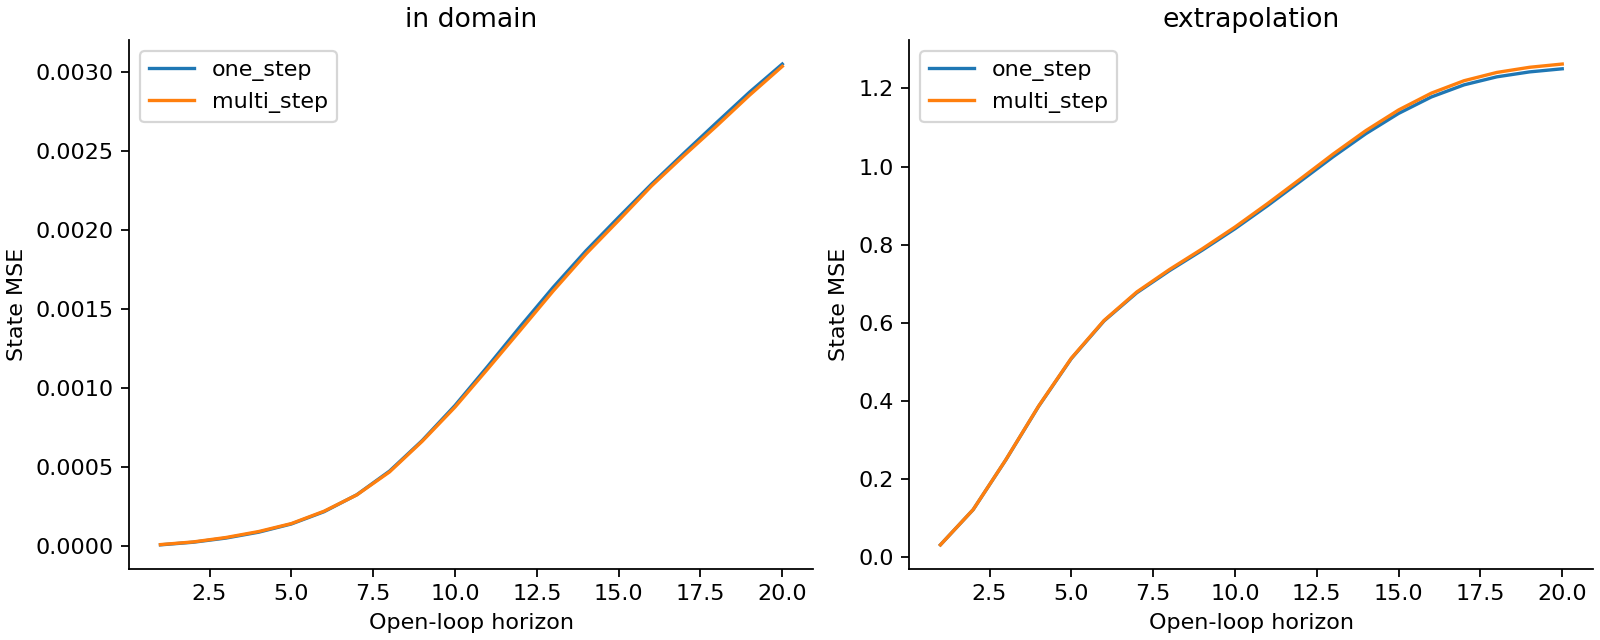

02_trajectory_predictions.png


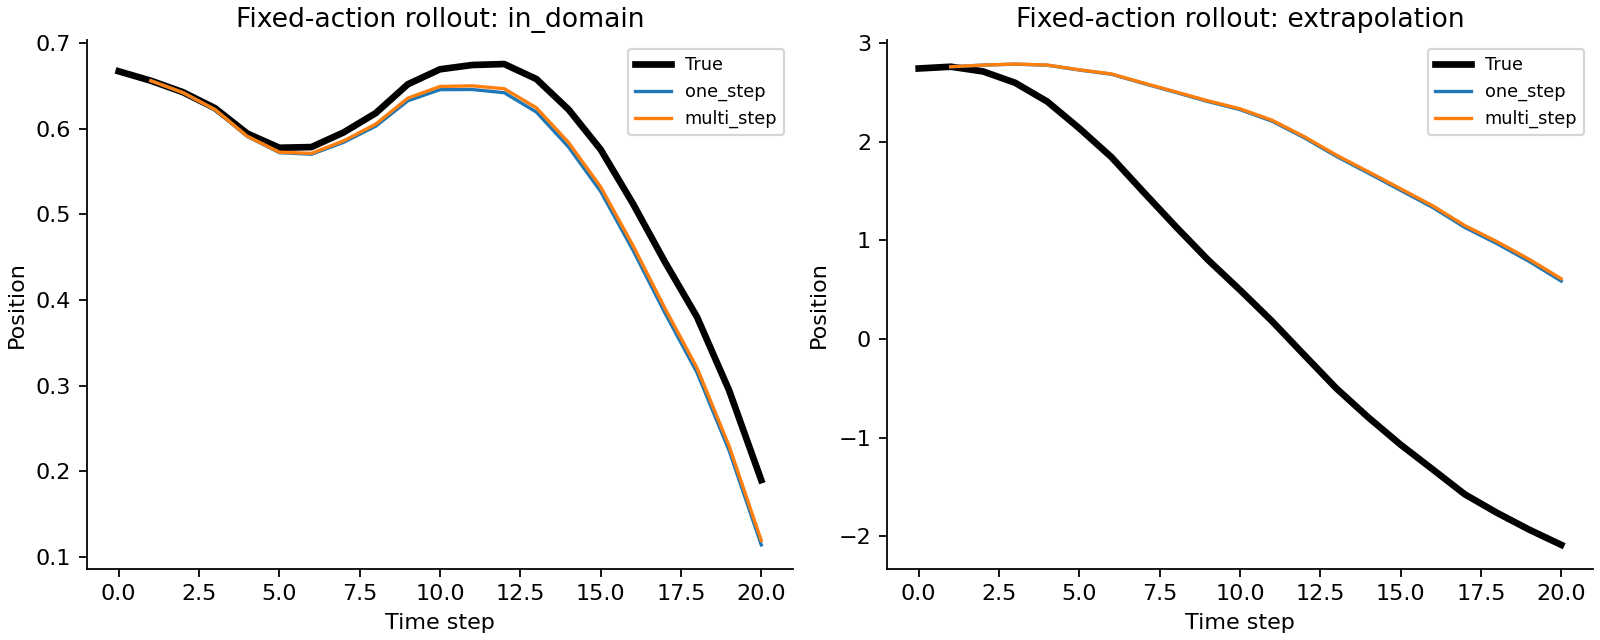

03_control_trajectories.png


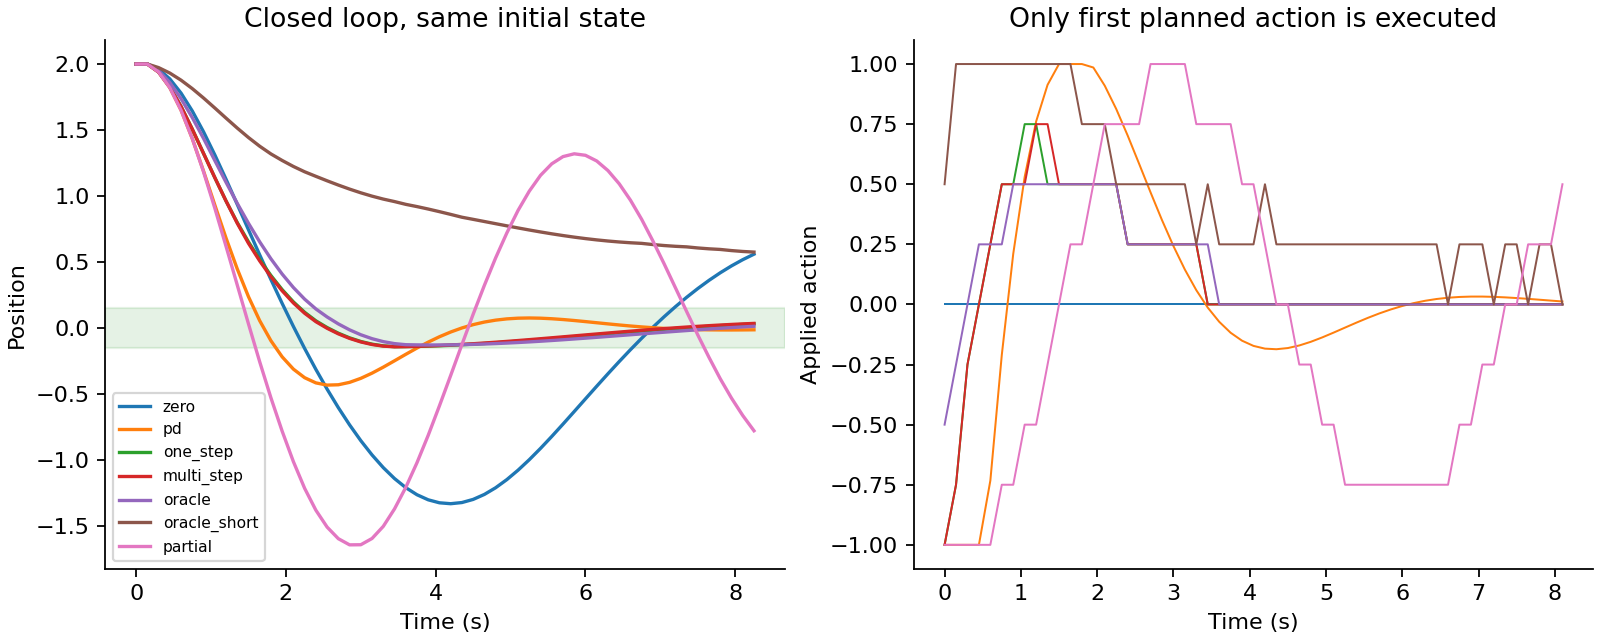

04_cost_failure.png


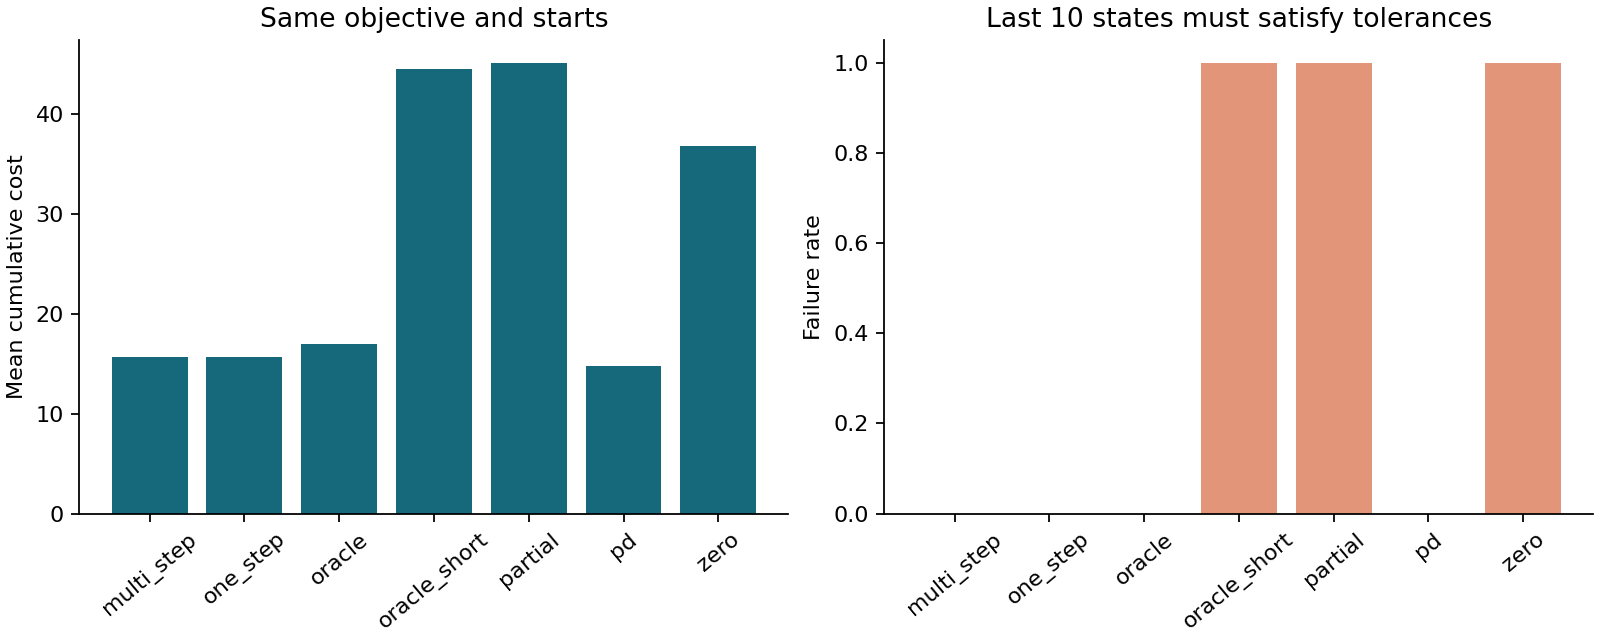

05_partial_distribution.png


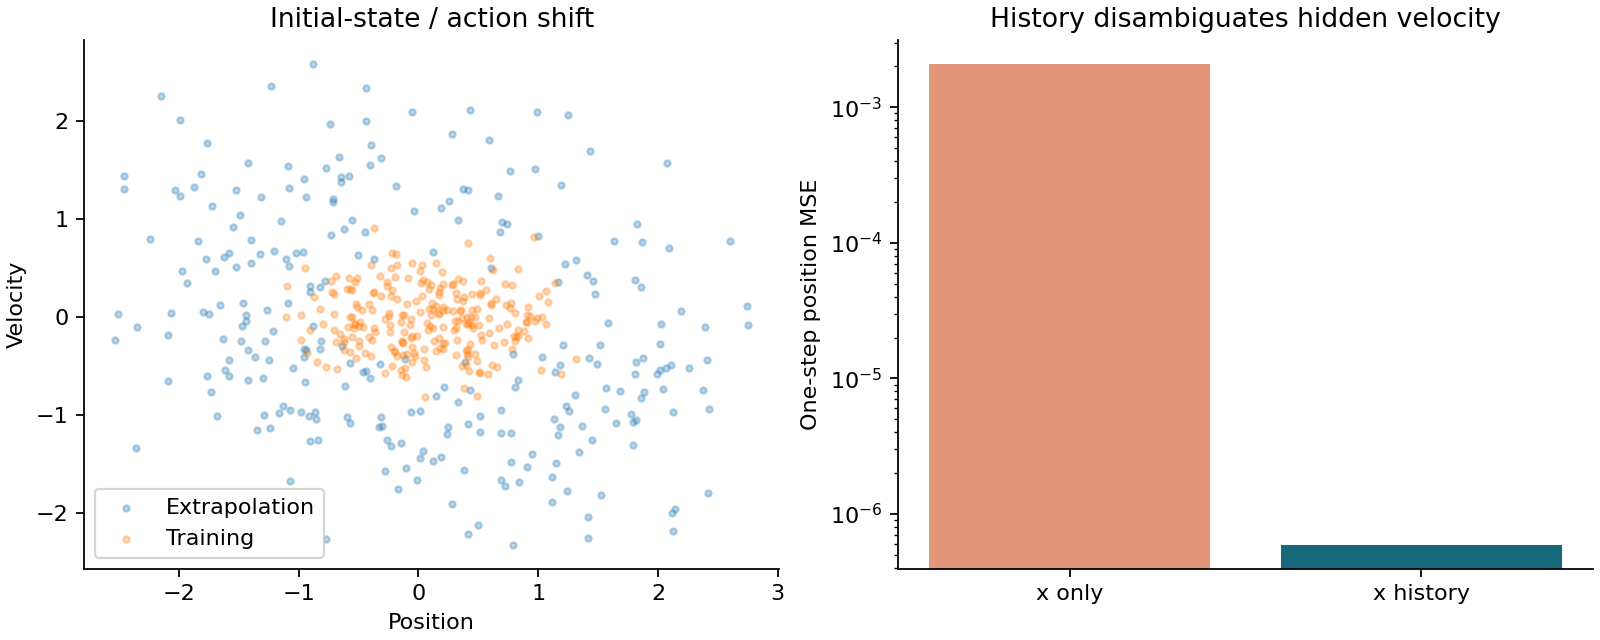

06_planning_loop.png


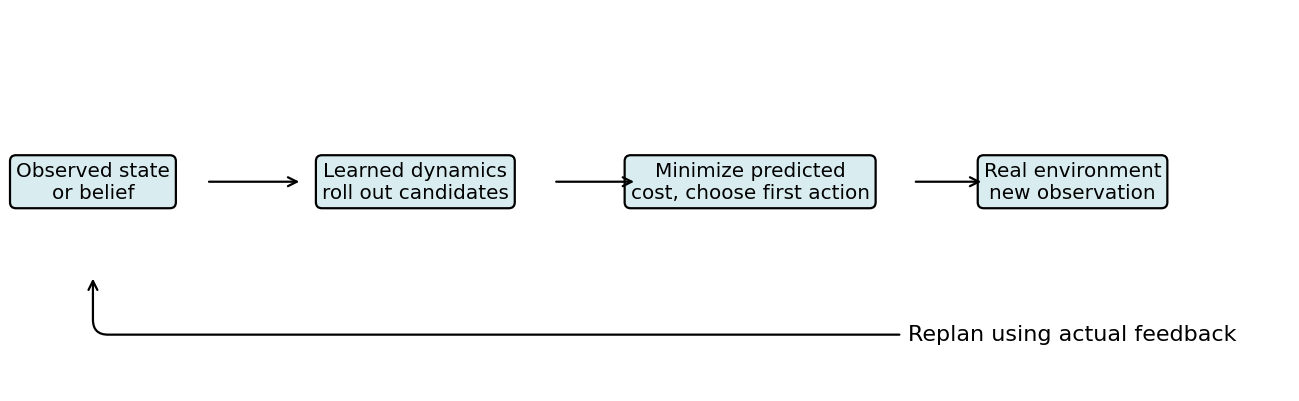

In [7]:
from IPython.display import display,Image
for path in sorted(Path("figures").glob("*.png")):
    print(path.name)
    display(Image(filename=str(path)))

## 研究记录
请写下一个受证据支持的主张、一个负结果或限制、一个明确的新检验。不要用参考答案替代自己的数据检查。

In [8]:
print("Saved outputs:",sorted(p.name for p in Path("outputs").iterdir() if p.is_file()))

Saved outputs: ['control.csv', 'data.npz', 'metrics.json', 'prediction.csv', 'predictions.npz', 'replay-verification.json', 'weights.npz']
